# Dummy Catastrophe Model, UK Flood Risk — Notebook 03: Flood Frequency, Expected Annual Loss and Portfolio Risk

**Objective:** Build on Notebooks 01 and 02 by combining annual flood probabilities with illustrative insurer-paid losses. 

This notebook calculates expected annual loss (EAL), simulates annual portfolio losses, compares regional risk contributions, and tests alternative assumptions.

> **Limitation:** This is a synthetic learning exercise, not an industry catastrophe model. Property flood occurrences are treated as independent. Real flood events can affect many properties simultaneously, creating correlated and accumulated losses. This simulation does not reproduce shared event footprints.

## 1. Load the portfolio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("synthetic_uk_flood_portfolio_1000_geocoded.csv")
print(f"Loaded {len(df):,} properties")
display(df.head())

Loaded 1,000 properties


,property_id,region,area,latitude,longitude,property_type,year_built,building_sum_insured_gbp,contents_sum_insured_gbp,total_sum_insured_gbp,deductible_gbp,policy_limit_gbp,illustrative_flood_zone,annual_flood_probability,baseline_flood_depth_m
0,P0001,East Anglia,Cambridge,52.153420,0.105548,Terraced,1932,147000,25000,172000,7500,185000,Medium,0.01539,0.182
1,P0002,East Anglia,Cambridge,52.235736,0.166611,Commercial,1929,460000,59000,519000,7500,460000,Low,0.00555,0.082
2,P0003,Yorkshire,York,53.922544,-1.083690,Flat,1981,170000,34000,204000,7500,175000,High,0.03961,0.442
3,P0004,Thames Valley,Reading,51.454193,-0.971377,Commercial,1913,553000,69000,622000,5000,610000,Low,0.00406,0.115
4,P0005,Severn Basin,Gloucester,51.877088,-2.270219,Semi-detached,1965,176000,50000,226000,5000,195000,High,0.04003,0.456


## 2. Recreate the illustrative loss calculation

This repeats the vulnerability curve and insurance payment logic from Notebook 02. We assume the loss generated from baseline flood depth represents the loss conditional on the flood scenario occurring. The synthetic data does not validate that assumption.

In [2]:
depth_anchors_m = np.array([0.00, 0.10, 0.25, 0.50, 1.00, 1.50, 2.00, 3.00])
damage_anchors = np.array([0.00, 0.02, 0.08, 0.20, 0.45, 0.65, 0.80, 0.95])

def depth_to_damage_ratio(depth_m):
    return np.interp(np.asarray(depth_m, dtype=float),
                     depth_anchors_m, damage_anchors,
                     left=0.0, right=damage_anchors[-1])

df["damage_ratio"] = depth_to_damage_ratio(df["baseline_flood_depth_m"])
df["gross_damage_gbp"] = df["total_sum_insured_gbp"] * df["damage_ratio"]
df["loss_after_deductible_gbp"] = (df["gross_damage_gbp"] - df["deductible_gbp"]).clip(lower=0)
df["insurer_paid_loss_gbp"] = np.minimum(df["loss_after_deductible_gbp"], df["policy_limit_gbp"])
df["policyholder_retained_gbp"] = (df["gross_damage_gbp"] - df["insurer_paid_loss_gbp"]).clip(lower=0)

assert df["annual_flood_probability"].between(0, 1).all()
assert (df["insurer_paid_loss_gbp"] >= 0).all()
assert (df["insurer_paid_loss_gbp"] <= df["policy_limit_gbp"] + 1e-8).all()
assert np.allclose(df["gross_damage_gbp"], df["insurer_paid_loss_gbp"] + df["policyholder_retained_gbp"])

print(f"Portfolio TIV: £{df['total_sum_insured_gbp'].sum():,.0f}")
print(f"Scenario insurer-paid loss if all properties flood: £{df['insurer_paid_loss_gbp'].sum():,.0f}")

Portfolio TIV: £345,843,000
Scenario insurer-paid loss if all properties flood: £21,102,189


## 3. Calculate illustrative expected annual loss

For a simple binary annual occurrence model:
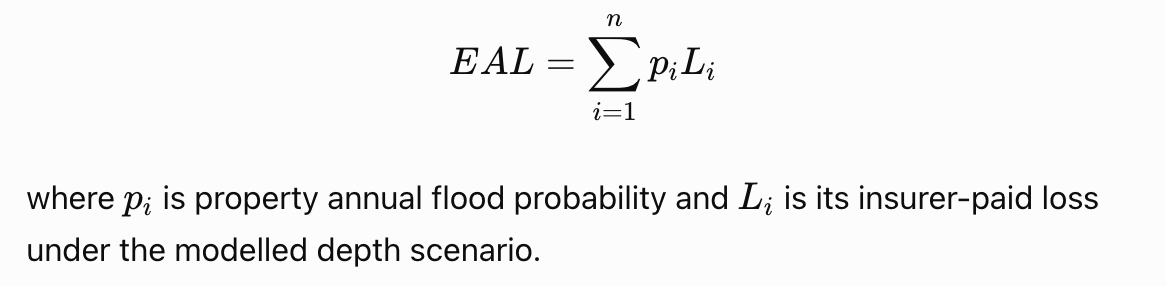

This assumes baseline-depth loss is conditional on the relevant flood occurrence. Treat the result as illustrative, not a validated forecast or calibrated actuarial estimate. EAL is a long-run average, not the amount paid every year.

In [3]:
df["expected_annual_loss_gbp"] = df["annual_flood_probability"] * df["insurer_paid_loss_gbp"]
eal_total = df["expected_annual_loss_gbp"].sum()
scenario_loss_total = df["insurer_paid_loss_gbp"].sum()

print(f"Illustrative portfolio EAL: £{eal_total:,.0f}")
print(f"Scenario loss if all properties flood: £{scenario_loss_total:,.0f}")
print(f"EAL / scenario loss: {eal_total / scenario_loss_total:.2%}")

Illustrative portfolio EAL: £474,957
Scenario loss if all properties flood: £21,102,189
EAL / scenario loss: 2.25%


With this model, we assume:
1. The annual probability reasonably represents the chance of the flood event occurring in any given year.
2. The scenario loss is a reasonable estimate of the insurer's payment if that event occurs.
3. The probability and conditional loss are appropriately matched to the same event or hazard conditions.
4. The probability and loss assumptions remain sufficiently stable over time.

## 4. Compare expected annual loss by region

Compare each region's share of EAL with its share of total insured value (TIV).

In [4]:
regional = df.groupby("region").agg(
    property_count=("property_id", "count"),
    total_tiv_gbp=("total_sum_insured_gbp", "sum"),
    mean_annual_probability=("annual_flood_probability", "mean"),
    scenario_insurer_loss_gbp=("insurer_paid_loss_gbp", "sum"),
    expected_annual_loss_gbp=("expected_annual_loss_gbp", "sum")
)
regional["tiv_share"] = regional["total_tiv_gbp"] / df["total_sum_insured_gbp"].sum()
regional["eal_share"] = regional["expected_annual_loss_gbp"] / eal_total
regional["eal_per_1m_tiv"] = regional["expected_annual_loss_gbp"] / regional["total_tiv_gbp"] * 1_000_000
regional = regional.sort_values("expected_annual_loss_gbp", ascending=False)
display(regional.style.format({
    "total_tiv_gbp": "£{:,.0f}", "mean_annual_probability": "{:.2%}",
    "scenario_insurer_loss_gbp": "£{:,.0f}", "expected_annual_loss_gbp": "£{:,.0f}",
    "tiv_share": "{:.1%}", "eal_share": "{:.1%}", "eal_per_1m_tiv": "£{:,.0f}"
}))

,property_count,total_tiv_gbp,mean_annual_probability,scenario_insurer_loss_gbp,expected_annual_loss_gbp,tiv_share,eal_share,eal_per_1m_tiv
region,,,,,,,,
Severn Basin,243,"£85,630,000",1.74%,"£7,125,772","£190,992",24.8%,40.2%,"£2,230"
Yorkshire,262,"£91,186,000",1.42%,"£5,562,905","£119,044",26.4%,25.1%,"£1,306"
Thames Valley,235,"£78,654,000",1.31%,"£4,917,989","£99,868",22.7%,21.0%,"£1,270"
East Anglia,260,"£90,373,000",1.20%,"£3,495,523","£65,052",26.1%,13.7%,£720


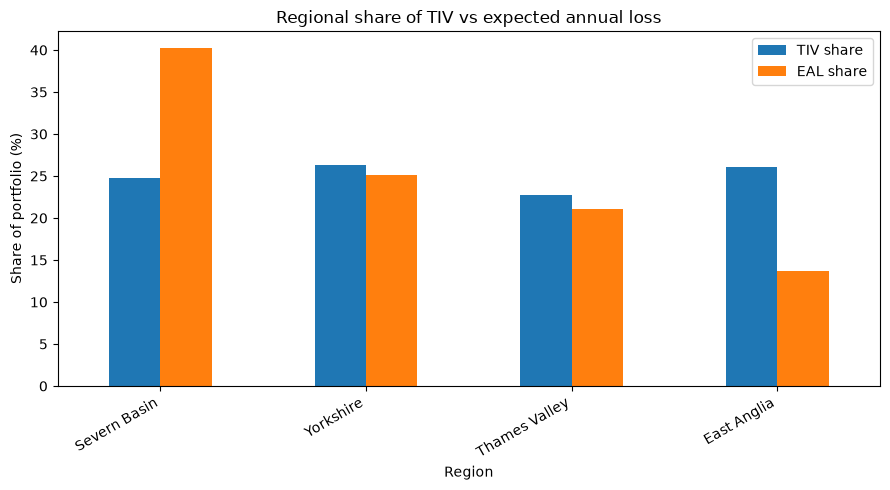

In [5]:
plot_data = regional[["tiv_share", "eal_share"]] * 100
ax = plot_data.plot(kind="bar", figsize=(9, 5))
ax.set_title("Regional share of TIV vs expected annual loss")
ax.set_xlabel("Region")
ax.set_ylabel("Share of portfolio (%)")
ax.legend(["TIV share", "EAL share"])
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Interpretation
This highlights well the compounding of the factors acknowledged in Notebook 01 and 02 for the Severn Basin. TIV share is consistent across the region but the Severn Basin is likely to hold a significantly higher annualised loss.

EAL depends on both the probability assumption and conditional insurer-paid loss, not TIV alone.

## 5. Simulate annual portfolio losses

For each simulated year and property, draw whether its flood scenario occurs using its annual probability. If it occurs, include the property's modelled insurer-paid loss; otherwise, assign zero.

**Key assumption:** property occurrences are independent. This does not model shared flood events or correlated losses and may materially misrepresent accumulation risk.

In [6]:
n_simulations = 10_000
rng = np.random.default_rng(42)
probabilities = df["annual_flood_probability"].to_numpy(dtype=float)
conditional_losses = df["insurer_paid_loss_gbp"].to_numpy(dtype=float)

occurrences = rng.random((n_simulations, len(df))) < probabilities
annual_losses = (occurrences * conditional_losses).sum(axis=1)
simulation = pd.DataFrame({
    "simulation_year": np.arange(1, n_simulations + 1),
    "annual_portfolio_loss_gbp": annual_losses
})
display(simulation.head(10))

,simulation_year,annual_portfolio_loss_gbp
0,1,607161.04
1,2,34674.24
2,3,864595.78
3,4,510568.30
4,5,495929.48
5,6,335492.46
6,7,645482.22
7,8,521701.44
8,9,491294.88
9,10,396894.60


## 6. Examine the annual loss distribution

Compare simulated mean loss with analytical EAL. With enough simulations, the two should be reasonably close, although Monte Carlo variation means they will not be identical.

Analytical EAL: £474,957
Simulated mean annual loss: £473,837
Difference: -0.24%
Standard deviation: £230,176


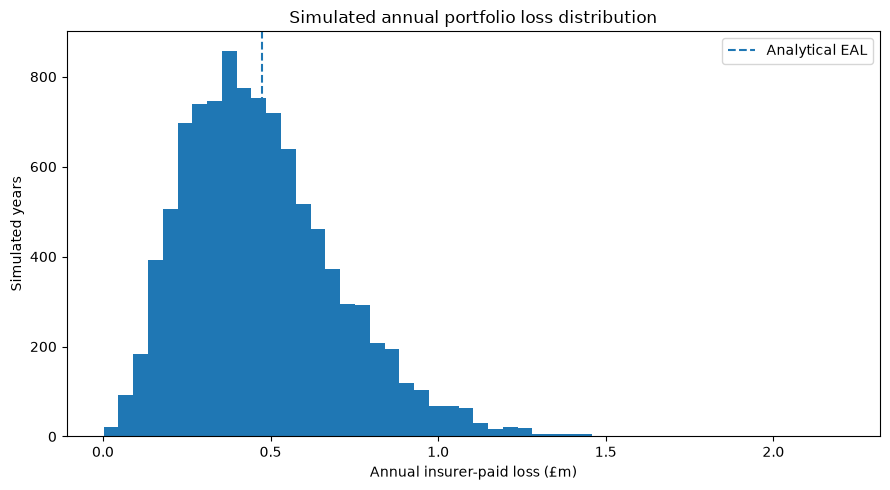

In [7]:
simulated_mean = simulation["annual_portfolio_loss_gbp"].mean()
simulated_std = simulation["annual_portfolio_loss_gbp"].std()
print(f"Analytical EAL: £{eal_total:,.0f}")
print(f"Simulated mean annual loss: £{simulated_mean:,.0f}")
print(f"Difference: {(simulated_mean - eal_total) / eal_total:.2%}")
print(f"Standard deviation: £{simulated_std:,.0f}")

plt.figure(figsize=(9, 5))
plt.hist(annual_losses / 1_000_000, bins=50)
plt.axvline(eal_total / 1_000_000, linestyle="--", label="Analytical EAL")
plt.title("Simulated annual portfolio loss distribution")
plt.xlabel("Annual insurer-paid loss (£m)")
plt.ylabel("Simulated years")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Examine high-loss outcomes

The 95th and 99th percentiles describe annual loss thresholds exceeded in approximately 5% and 1% of simulated years. The tail mean is the average loss among outcomes at or above the 99th percentile.

These are empirical simulation statistics, not regulatory capital measures or validated catastrophe-model outputs. With 10,000 simulations, the 99th percentile is based on roughly 100 tail outcomes and can be noisy.

In [8]:
losses = simulation["annual_portfolio_loss_gbp"].to_numpy()
var_95 = np.quantile(losses, 0.95)
var_99 = np.quantile(losses, 0.99)
tail_mean_99 = losses[losses >= var_99].mean()

metrics = pd.Series({
    "Mean annual loss (£)": losses.mean(),
    "95th percentile annual loss (£)": var_95,
    "99th percentile annual loss (£)": var_99,
    "Mean loss at/above 99th percentile (£)": tail_mean_99,
    "Maximum simulated annual loss (£)": losses.max(),
    "Share of simulated years with zero loss": (losses == 0).mean()
})
display(metrics.to_frame("value").style.format({
    "value": lambda x: f"{x:.1%}" if x <= 1 else f"£{x:,.0f}"
}))

,value
Mean annual loss (£),"£473,837"
95th percentile annual loss (£),"£895,435"
99th percentile annual loss (£),"£1,128,533"
Mean loss at/above 99th percentile (£),"£1,265,113"
Maximum simulated annual loss (£),"£2,207,909"
Share of simulated years with zero loss,0.0%


### Return-period interpretation

For an annual loss threshold, empirical annual exceedance probability (AEP) is the proportion of simulated years in which loss exceeds the threshold. A rough return-period interpretation is the reciprocal of AEP. A 1% AEP corresponds to a 100-year return period under a stationary assumption; it does not mean an event happens exactly once every 100 years.

In [9]:
rows = []
for label, threshold in zip(
    ["90th percentile", "95th percentile", "99th percentile"],
    np.quantile(losses, [0.90, 0.95, 0.99])
):
    aep = np.mean(losses >= threshold)
    rows.append({
        "Threshold": label, "Loss (£)": threshold,
        "Empirical AEP": aep,
        "Approximate return period (years)": 1 / aep if aep > 0 else np.inf
    })
display(pd.DataFrame(rows).style.format({
    "Loss (£)": "£{:,.0f}", "Empirical AEP": "{:.2%}",
    "Approximate return period (years)": "{:.1f}"
}))

,Threshold,Loss (£),Empirical AEP,Approximate return period (years)
0,90th percentile,"£783,952",10.00%,10.0
1,95th percentile,"£895,435",5.00%,20.0
2,99th percentile,"£1,128,533",1.00%,100.0


## 8. Stress-test flood depth

Increase every property's baseline depth by 25%, 50% and 100%, recalculate vulnerability and insurer payment, then recalculate EAL using unchanged annual probabilities.

This is a **severity stress test**, not a climate-change projection. It assumes a uniform depth change and does not alter event probabilities, flood footprints or correlations.

In [10]:
depth_multipliers = [1.00, 1.25, 1.50, 2.00]
stress_rows = []
for multiplier in depth_multipliers:
    depth = df["baseline_flood_depth_m"].to_numpy() * multiplier
    ratio = depth_to_damage_ratio(depth)
    gross = df["total_sum_insured_gbp"].to_numpy() * ratio
    after_deductible = np.maximum(gross - df["deductible_gbp"].to_numpy(), 0)
    insurer_loss = np.minimum(after_deductible, df["policy_limit_gbp"].to_numpy())
    stress_eal = np.sum(probabilities * insurer_loss)
    stress_rows.append({
        "Depth multiplier": multiplier,
        "Gross damage (£)": gross.sum(),
        "Insurer-paid scenario loss (£)": insurer_loss.sum(),
        "Illustrative EAL (£)": stress_eal
    })

stress = pd.DataFrame(stress_rows)
stress["EAL change vs baseline (%)"] = (stress["Illustrative EAL (£)"] / eal_total - 1) * 100
display(stress.style.format({
    "Depth multiplier": "{:.2f}x", "Gross damage (£)": "£{:,.0f}",
    "Insurer-paid scenario loss (£)": "£{:,.0f}",
    "Illustrative EAL (£)": "£{:,.0f}",
    "EAL change vs baseline (%)": "{:+.1f}%"
}))

,Depth multiplier,Gross damage (£),Insurer-paid scenario loss (£),Illustrative EAL (£),EAL change vs baseline (%)
0,1.00x,"£25,772,559","£21,102,189","£474,957",+0.0%
1,1.25x,"£33,769,781","£28,851,082","£634,554",+33.6%
2,1.50x,"£41,785,215","£36,676,787","£791,266",+66.6%
3,2.00x,"£57,330,649","£51,964,655","£1,085,783",+128.6%


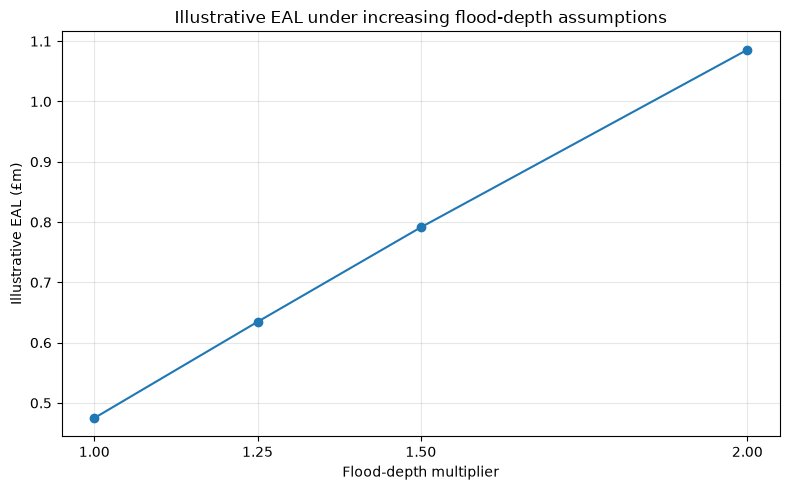

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(stress["Depth multiplier"], stress["Illustrative EAL (£)"] / 1_000_000, marker="o")
plt.title("Illustrative EAL under increasing flood-depth assumptions")
plt.xlabel("Flood-depth multiplier")
plt.ylabel("Illustrative EAL (£m)")
plt.xticks(depth_multipliers)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation
- The relationship is not in direct proportion, doubling the flood depth more than doubles EAL.
- Recall the vulnerability curve is non-linear and this influences the EAL for greater depths.

- We still have not considered things like flood defence, the correlation of flood losses across properties and longer term (multi-annual) patterns in flood occurrence/severity. These would all need to form part of a model used for udnerwriting strategy.

## 9. Sensitivity to annual flood probabilities

Change annual probabilities while holding conditional losses constant. This isolates the frequency assumption. Multipliers are illustrative; probabilities are capped at 100%.

In [12]:
probability_multipliers = [0.5, 1.0, 1.5, 2.0]
prob_rows = []
for multiplier in probability_multipliers:
    adjusted_p = np.clip(probabilities * multiplier, 0, 1)
    adjusted_eal = np.sum(adjusted_p * conditional_losses)
    prob_rows.append({
        "Probability multiplier": multiplier,
        "Mean adjusted annual probability": adjusted_p.mean(),
        "Illustrative EAL (£)": adjusted_eal,
        "Change vs baseline EAL (%)": (adjusted_eal / eal_total - 1) * 100
    })
prob_sensitivity = pd.DataFrame(prob_rows)
display(prob_sensitivity.style.format({
    "Probability multiplier": "{:.1f}x",
    "Mean adjusted annual probability": "{:.2%}",
    "Illustrative EAL (£)": "£{:,.0f}",
    "Change vs baseline EAL (%)": "{:+.1f}%"
}))

,Probability multiplier,Mean adjusted annual probability,Illustrative EAL (£),Change vs baseline EAL (%)
0,0.5x,0.71%,"£237,478",-50.0%
1,1.0x,1.41%,"£474,957",+0.0%
2,1.5x,2.12%,"£712,435",+50.0%
3,2.0x,2.83%,"£949,913",+100.0%


## 10. Final validation checks

In [13]:
assert len(df) == 1000
assert df["annual_flood_probability"].between(0, 1).all()
assert df["baseline_flood_depth_m"].ge(0).all()
assert (df["gross_damage_gbp"] >= 0).all()
assert (df["insurer_paid_loss_gbp"] >= 0).all()
assert (df["insurer_paid_loss_gbp"] <= df["gross_damage_gbp"] + 1e-8).all()
assert (df["insurer_paid_loss_gbp"] <= df["policy_limit_gbp"] + 1e-8).all()
assert np.isclose(eal_total, np.sum(probabilities * conditional_losses))
assert len(simulation) == n_simulations
assert (simulation["annual_portfolio_loss_gbp"] >= 0).all()
assert np.isfinite(simulation["annual_portfolio_loss_gbp"]).all()
print("All validation checks passed.")
print(f"Analytical EAL: £{eal_total:,.0f}")
print(f"Simulated mean annual loss: £{simulated_mean:,.0f}")

All validation checks passed.
Analytical EAL: £474,957
Simulated mean annual loss: £473,837


## 11. Analyst interpretation

The portfolio has an illustrative Expected Annual Loss (EAL) of approximately £475,000, based on the assumed annual flood probabilities and conditional insurer-paid losses. Severn Basin contributes the largest share of EAL at 40.2%, despite representing only 24.8% of total insured value (TIV). This disproportionate contribution suggests a concentration of risk that warrants further investigation when considering underwriting appetite and portfolio accumulation.

The annual loss distribution provides additional insight beyond the average. The simulated 95th percentile annual loss is approximately £895,000, rising to £1.13m at the 99th percentile, with the maximum simulated loss reaching £2.21m. This illustrates the potential for annual losses to materially exceed the long-term average. The simulated mean of £474,000 is also close to the analytical EAL, providing a useful consistency check.

Depth sensitivity testing demonstrates significant exposure to worsening flood severity. A 25%, 50% and 100% increase in baseline depth raises EAL by approximately 33.6%, 66.6% and 128.6%, respectively.

However, the independent-property simulation does not capture correlated losses from shared flood events, potentially misrepresenting portfolio accumulation. I would recommend developing a geographically coherent event set, incorporating shared flood footprints and calibrated hazard and vulnerability assumptions, to provide a more robust basis for underwriting and risk management decisions.